In [140]:
#pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import re

# Load the new CSV file to inspect its contents
#new_file_path = r"C:\Users\김진하\Documents\VSCODE\A_DocMal\Mail_Maker\preprocessed_contagio_dataset_version_v0.2.csv"
#new_df = pd.read_csv(new_file_path)
result_ben = pd.read_csv('/home/user2/~/A-Awake/src/Python/Data/result_ben.csv')
result_mal = pd.read_csv('/home/user2/~/A-Awake/src/Python/Data/result_mal.csv')

# Display the first few rows of the new dataframe to understand its structure
#라벨링 (정상0, 악성1)
result_ben['label'] = 0
result_mal['label'] = 1

# 두 데이터 병합
data = pd.concat([result_ben, result_mal], ignore_index=True)

In [3]:
data

,name,pdfsize,metadata size,pages,xref length,title characters,isEncrypted,embedded files,contains text,PDF,...,/OpenAction,/AcroForm,/JBIG2Decode,/RichMedia,/Launch,/EmbeddedFile,/XFA,/Colors,label,Not
0,dd3d91f126124f6f32355b0acffb87d07989be8d,313028,334,9,-1,21,0,0,Yes,%PDF-1.3,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0,NaN
1,f1668ef96d8900294d86b1979b977c0b75e753f6,43430,249,1,-1,0,0,0,Yes,%PDF-1.7,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0,NaN
2,e687b985c2fa8d140d20e064233ca7e91d26231b,189257,271,3,-1,0,0,0,Yes,%PDF-1.4,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0,NaN
3,21ab8235aeb7263e3f9196cffe99ae3dbfcf45cc,1283965,218,2,-1,0,0,0,Yes,%PDF-1.5,...,0,1.0,0.0,0.0,0,0.0,0.0,0.0,0,NaN
4,9456b54cf0a67ece7dd7468a5a8c012e30c4dc9a,705225,280,16,-1,0,0,0,Yes,%PDF-1.4,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396,426649c2297928ed6d6a397cb4db8dabcc25ecee,63948,203,1,-1,0,0,0,Yes,%PDF-1.3,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,1,NaN
397,192f767c2d27966f50109fb62ff645fe38cc8d97,710973,272,2,-1,0,0,0,Yes,%PDF-1.5,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,1,NaN
398,e9d2b4f151a21cc29c32dd7f8e650e2b7ca44625,25332,4,1,-1,Except,-1,0,unclear,%PDF-2.0,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,1,NaN
399,d09861b8121449280ee51887de55ba5e1348398b,54226,217,1,-1,0,0,0,Yes,%PDF-1.7,...,0,1.0,0.0,0.0,0,0.0,0.0,0.0,1,NaN


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler
from scipy import stats

# 1. 불필요한 열 제거 (name, Not, PDF)
df_cleaned = data.drop(columns=['name', 'Not', 'PDF'], errors='ignore')

# 2. 문자열 값 처리: 정규 표현식을 사용하여 숫자만 추출
def extract_numeric_value(value):
    if isinstance(value, str):
        match = re.search(r'\d+', value)  # 문자열에서 숫자만 추출
        if match:
            return float(match.group())
    return value

# 숫자로 변환할 수 없는 값 처리
df_cleaned = df_cleaned.applymap(extract_numeric_value)

# 3. 문자열 'Except'를 가진 값을 0으로 대체
df_cleaned.replace('Except', 0, inplace=True)

# 4. 결측값 처리 (결측값 삭제)
df_cleaned.fillna(0, inplace=True) 

# 특정 열에 값이 0인 행 제거 (pdfsize가 0인 경우)
df_cleaned = df_cleaned[df_cleaned['pdfsize'] > 0]

# 5. 범주형 데이터 인코딩
label_encoder = LabelEncoder()

# 'contains text' 열에 대해서만 범주형 데이터를 숫자형으로 변환
if 'contains text' in df_cleaned.columns:
    df_cleaned['contains text'] = label_encoder.fit_transform(df_cleaned['contains text'])

# 다른 범주형 데이터도 One-Hot Encoding
df_cleaned = pd.get_dummies(df_cleaned, drop_first=True)

/tmp/ipykernel_5366/282515412.py:19: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_cleaned = df_cleaned.applymap(extract_numeric_value)
/tmp/ipykernel_5366/282515412.py:22: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_cleaned.replace('Except', 0, inplace=True)


In [5]:
df_cleaned

,pdfsize,metadata size,pages,xref length,title characters,isEncrypted,embedded files,contains text,obj,endobj,...,/AA,/OpenAction,/AcroForm,/JBIG2Decode,/RichMedia,/Launch,/EmbeddedFile,/XFA,/Colors,label
0,313028,334,9,-1,21.0,0,0,1,81.0,81.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,43430,249,1,-1,0.0,0,0,1,22.0,22.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,189257,271,3,-1,0.0,0,0,1,51.0,51.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,1283965,218,2,-1,0.0,0,0,1,624.0,624.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,705225,280,16,-1,0.0,0,0,1,1549.0,1549.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396,63948,203,1,-1,0.0,0,0,1,24.0,24.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
397,710973,272,2,-1,0.0,0,0,1,41.0,41.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
398,25332,4,1,-1,0.0,-1,0,2,10.0,10.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
399,54226,217,1,-1,0.0,0,0,1,22.0,22.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1


In [6]:
df_cleaned.columns

Index(['pdfsize', 'metadata size', 'pages', 'xref length', 'title characters',
       'isEncrypted', 'embedded files', 'contains text', 'obj', 'endobj',
       'stream', 'endstream', 'xref', 'trailer', 'startxref', '/Page',
       '/Encrypt', '/ObjStm', '/JS', '/JavaScript', '/AA', '/OpenAction',
       '/AcroForm', '/JBIG2Decode', '/RichMedia', '/Launch', '/EmbeddedFile',
       '/XFA', '/Colors', 'label'],
      dtype='object')

In [18]:
from imblearn.over_sampling import SMOTE
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold

# 데이터 정규화
scaler = StandardScaler()
X = df_cleaned.drop(columns=['label'])
y = df_cleaned['label']
X_scaled = scaler.fit_transform(X)

# 데이터 증강 (SMOTE 사용)
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)

# 7. 상수 피처 제거
variance_threshold = VarianceThreshold(threshold=0)
X_filtered = variance_threshold.fit_transform(X_resampled)

# 특징 선택 (상위 10개의 특징 선택)
selector = SelectKBest(score_func=f_classif, k=10)
X_selected = selector.fit_transform(X_filtered, y_resampled)

# 선택된 피처 인덱스
selected_indices = selector.get_support(indices=True)

# 선택된 피처의 이름 출력
selected_features = X.columns[selected_indices]
print("Selected features are:")
print(selected_features)


# 데이터 분리 (Train/Test Split)
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_resampled, test_size=0.2, random_state=42)


Selected features are:
Index(['metadata size', 'xref length', 'embedded files', 'endobj', 'stream',
       'endstream', 'xref', '/AA', '/OpenAction', '/JBIG2Decode'],
      dtype='object')


In [19]:
X_selected

array([[ 1.27354935,  1.73177336,  0.67936228, ..., -0.35144211,
        -0.44386363, -0.15152288],
       [-0.05357559, -0.37624391,  0.67936228, ..., -0.35144211,
        -0.44386363, -0.15152288],
       [ 0.28991557, -0.37624391,  0.67936228, ..., -0.35144211,
        -0.44386363, -0.15152288],
       ...,
       [-1.13088877, -0.37624391, -1.25272477, ..., -0.35144211,
        -0.44386363, -0.15152288],
       [ 0.32568396, -0.37624391,  0.67936228, ..., -0.35144211,
        -0.44386363, -0.15152288],
       [ 0.0973239 , -0.37624391,  0.67936228, ..., -0.35144211,
        -0.44386363, -0.15152288]])

In [20]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

#  하이퍼파라미터 튜닝 (RandomForestClassifier)
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

rf_model = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf_model, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_

In [21]:
best_params

{'max_depth': 30,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 200}

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
import numpy as np
import pandas as pd
import joblib  # 모델 저장을 위한 joblib 추가

# 최적화된 랜덤포레스트 모델 훈련
best_rf_model = RandomForestClassifier(**best_params, random_state=42)
best_rf_model.fit(X_train, y_train)

# 랜덤포레스트 테스트 데이터 평가
y_pred_rf = best_rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_report = classification_report(y_test, y_pred_rf, output_dict=True)

# 결과 출력
print(f"Optimized Random Forest Accuracy: {rf_accuracy}")
print("Random Forest Classification Report:\n", classification_report(y_test, y_pred_rf))



Optimized Random Forest Accuracy: 0.825
Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.72      0.80        57
           1       0.78      0.92      0.85        63

    accuracy                           0.82       120
   macro avg       0.84      0.82      0.82       120
weighted avg       0.83      0.82      0.82       120



In [23]:
# 여러 모델 비교
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = {
    "Random Forest (Optimized)": {
        "accuracy": rf_accuracy,
        "precision_0": rf_report['0']['precision'],
        "recall_0": rf_report['0']['recall'],
        "f1_0": rf_report['0']['f1-score'],
        "precision_1": rf_report['1']['precision'],
        "recall_1": rf_report['1']['recall'],
        "f1_1": rf_report['1']['f1-score'],
    }
}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    
    results[name] = {
        "accuracy": accuracy,
        "precision_0": report['0']['precision'],
        "recall_0": report['0']['recall'],
        "f1_0": report['0']['f1-score'],
        "precision_1": report['1']['precision'],
        "recall_1": report['1']['recall'],
        "f1_1": report['1']['f1-score'],
    }

# 12. 결과 저장 및 모델 성능 비교
results_df = pd.DataFrame(results).T
best_model_name = results_df['accuracy'].idxmax()  # 가장 높은 정확도의 모델 선택
best_model = models.get(best_model_name, best_rf_model)  # 최적화된 랜덤포레스트와 비교


In [24]:
results_df

,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1
Random Forest (Optimized),0.825,0.891304,0.719298,0.796117,0.783784,0.920635,0.846715
Logistic Regression,0.725,0.666667,0.842105,0.744186,0.812500,0.619048,0.702703
SVM,0.675,0.750000,0.473684,0.580645,0.642857,0.857143,0.734694
KNN,0.825,0.833333,0.789474,0.810811,0.818182,0.857143,0.837209
Gradient Boosting,0.825,0.860000,0.754386,0.803738,0.800000,0.888889,0.842105


In [30]:
import joblib

# 학습된 모델을 저장 (RandomForestClassifier 모델)
model_filename = '/home/user2/~/A-Awake/src/Python/Model/pdf_model.pkl'
joblib.dump(best_model, model_filename)
print(f"Model saved as {model_filename}")

Model saved as /home/user2/~/A-Awake/src/Python/Model/pdf_model.pkl


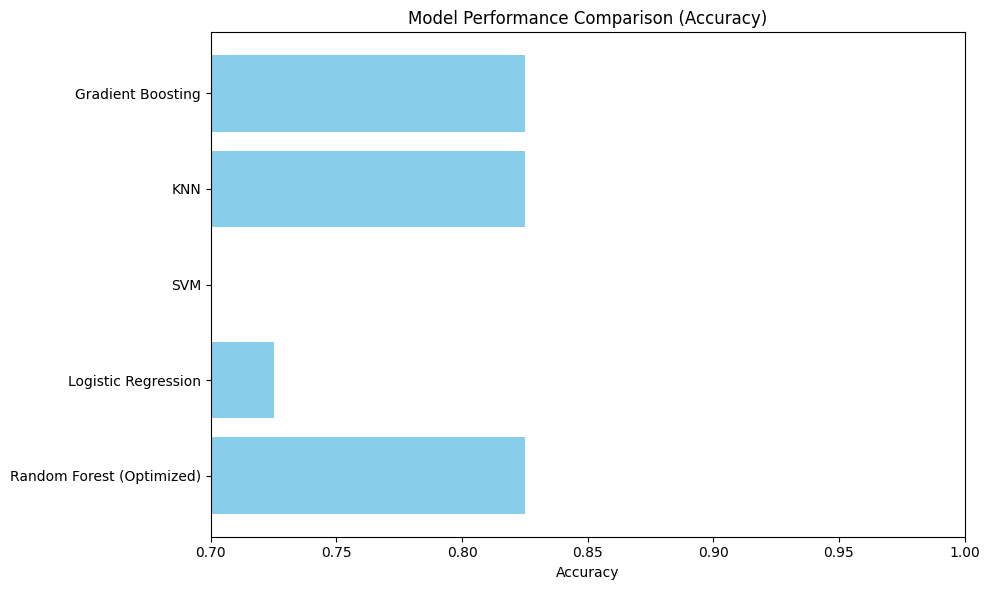

In [26]:
import matplotlib.pyplot as plt

# 모델 성능 시각화를 위한 데이터 추출
model_names = results_df.index
accuracies = results_df['accuracy']

# 정확도 시각화 (오차 막대는 제거)
plt.figure(figsize=(10, 6))
plt.barh(model_names, accuracies, color='skyblue', ecolor='black')
plt.xlabel('Accuracy')
plt.title('Model Performance Comparison (Accuracy)')
plt.xlim(0.7, 1.0)  # Adjusting limits to focus on high accuracy

# 그래프 레이아웃 정리 및 출력
plt.tight_layout()
plt.show()


In [27]:
loaded_model = joblib.load(model_filename)
y_pred = loaded_model.predict(X_test)

# 모델 평가 (예: 정확도)
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of loaded model: {accuracy}")

Accuracy of loaded model: 0.825
